<a href="https://colab.research.google.com/github/rmadatt/AI-Newton-StudyGroupAfrica/blob/main/QuantumEntanglement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== CHSH Bell test summary ===
Quantum: mean S = 2.829 ± 0.061, trials with S > 2: 100.0%
LHV:     mean S = 2.000 ± 0.078, trials with S > 2: 50.2%


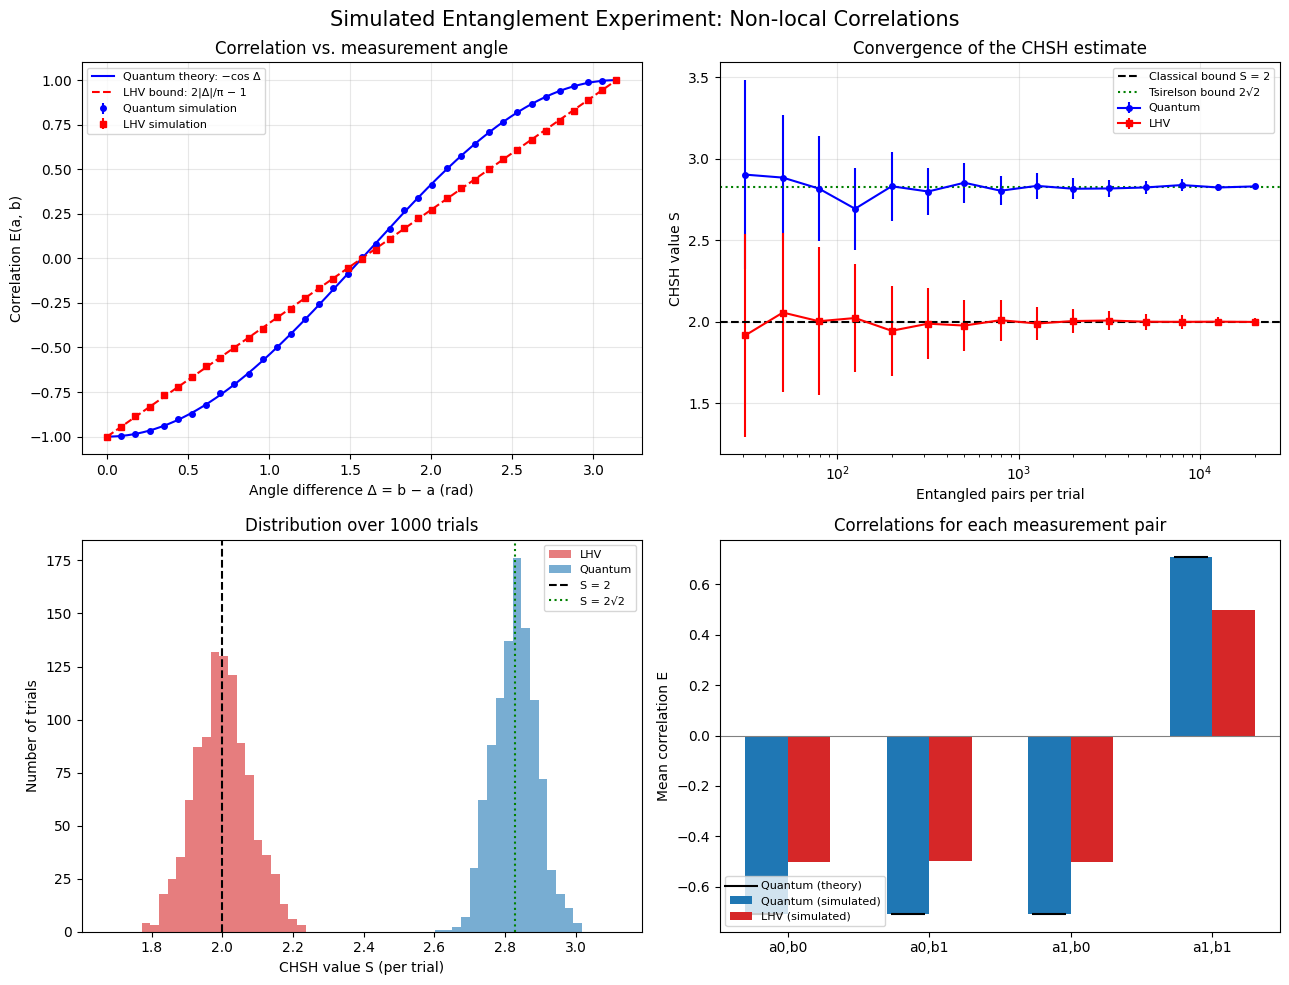

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 7
rng = np.random.default_rng(SEED)

# Measurement settings in radians (standard CHSH choice)
A_ANGLES = np.array([0.0, np.pi / 2])        # Alice: a0, a1
B_ANGLES = np.array([np.pi / 4, -np.pi / 4]) # Bob:   b0, b1

CLASSICAL_BOUND = 2.0
TSIRELSON_BOUND = 2 * np.sqrt(2)

N_TRIALS = 1000          # independent experimental runs
PAIRS_PER_TRIAL = 2000   # entangled pairs per run


# ---------------------------------------------------------------------------
# Models: each returns (alice_outcomes, bob_outcomes) in {-1, +1}
# ---------------------------------------------------------------------------
def quantum_outcomes(a, b, rng):
    """Singlet state: P(A*B = +1) = sin^2((a-b)/2), giving E(a,b) = -cos(a-b)."""
    alice = rng.choice([-1, 1], size=a.shape)
    p_same = np.sin((a - b) / 2) ** 2
    flip = rng.random(a.shape) < p_same
    bob = np.where(flip, alice, -alice)
    return alice, bob


def lhv_outcomes(a, b, rng):
    """Local hidden variable model: a shared angle lambda fixes both outcomes."""
    lam = rng.uniform(0, 2 * np.pi, size=a.shape)
    alice = np.sign(np.cos(a - lam))
    bob = -np.sign(np.cos(b - lam))
    return alice, bob


# ---------------------------------------------------------------------------
# Experiment: many trials, random setting choice for every pair
# ---------------------------------------------------------------------------
def run_trials(sampler, n_trials, n_pairs, rng):
    """Return per-trial correlation matrices E[trial, i, j] and CHSH values S[trial]."""
    a_idx = rng.integers(0, 2, size=(n_trials, n_pairs))
    b_idx = rng.integers(0, 2, size=(n_trials, n_pairs))
    alice, bob = sampler(A_ANGLES[a_idx], B_ANGLES[b_idx], rng)
    prod = alice * bob

    E = np.empty((n_trials, 2, 2))
    for i in range(2):
        for j in range(2):
            mask = (a_idx == i) & (b_idx == j)
            E[:, i, j] = np.sum(prod * mask, axis=1) / np.sum(mask, axis=1)

    # Sign convention chosen so that the singlet gives a positive S
    S = -(E[:, 0, 0] + E[:, 0, 1] + E[:, 1, 0] - E[:, 1, 1])
    return E, S


def sweep_correlation(sampler, deltas, n, rng):
    """Measure E(0, delta) for a range of angle differences."""
    means, errs = [], []
    for d in deltas:
        a = np.zeros(n)
        b = np.full(n, d)
        alice, bob = sampler(a, b, rng)
        p = alice * bob
        means.append(p.mean())
        errs.append(p.std(ddof=1) / np.sqrt(n))
    return np.array(means), np.array(errs)


def convergence(sampler, pair_counts, n_repeats, rng):
    """How the CHSH estimate and its spread change with the number of pairs."""
    means, stds = [], []
    for n in pair_counts:
        _, S = run_trials(sampler, n_repeats, n, rng)
        means.append(S.mean())
        stds.append(S.std(ddof=1))
    return np.array(means), np.array(stds)


# ---------------------------------------------------------------------------
# Theory curves
# ---------------------------------------------------------------------------
def theory_quantum(diff):
    return -np.cos(diff)


def theory_lhv(diff):
    # Triangle wave: E = 2|d|/pi - 1 with d the wrapped angle difference in [0, pi]
    return 2 * np.abs(np.angle(np.exp(1j * diff))) / np.pi - 1


# ---------------------------------------------------------------------------
# Run the experiments
# ---------------------------------------------------------------------------
deltas = np.linspace(0, np.pi, 37)
sw_q_mean, sw_q_err = sweep_correlation(quantum_outcomes, deltas, 20000, rng)
sw_l_mean, sw_l_err = sweep_correlation(lhv_outcomes, deltas, 20000, rng)

pair_counts = np.unique(np.logspace(1.5, 4.3, 15).astype(int))
conv_q_mean, conv_q_std = convergence(quantum_outcomes, pair_counts, 50, rng)
conv_l_mean, conv_l_std = convergence(lhv_outcomes, pair_counts, 50, rng)

E_q, S_q = run_trials(quantum_outcomes, N_TRIALS, PAIRS_PER_TRIAL, rng)
E_l, S_l = run_trials(lhv_outcomes, N_TRIALS, PAIRS_PER_TRIAL, rng)

print("=== CHSH Bell test summary ===")
print(f"Quantum: mean S = {S_q.mean():.3f} ± {S_q.std():.3f}, "
      f"trials with S > 2: {(S_q > CLASSICAL_BOUND).mean() * 100:.1f}%")
print(f"LHV:     mean S = {S_l.mean():.3f} ± {S_l.std():.3f}, "
      f"trials with S > 2: {(S_l > CLASSICAL_BOUND).mean() * 100:.1f}%")

# ---------------------------------------------------------------------------
# Plots
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("Simulated Entanglement Experiment: Non-local Correlations", fontsize=15)

# 1. Correlation vs measurement angle difference
ax = axes[0, 0]
fine = np.linspace(0, np.pi, 300)
ax.plot(fine, theory_quantum(fine), "b-", label="Quantum theory: −cos Δ")
ax.plot(fine, theory_lhv(fine), "r--", label="LHV bound: 2|Δ|/π − 1")
ax.errorbar(deltas, sw_q_mean, yerr=sw_q_err, fmt="bo", ms=4, label="Quantum simulation")
ax.errorbar(deltas, sw_l_mean, yerr=sw_l_err, fmt="rs", ms=4, label="LHV simulation")
ax.set_xlabel("Angle difference Δ = b − a (rad)")
ax.set_ylabel("Correlation E(a, b)")
ax.set_title("Correlation vs. measurement angle")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 2. CHSH value vs number of pairs
ax = axes[0, 1]
ax.errorbar(pair_counts, conv_q_mean, yerr=conv_q_std, fmt="bo-", ms=4, label="Quantum")
ax.errorbar(pair_counts, conv_l_mean, yerr=conv_l_std, fmt="rs-", ms=4, label="LHV")
ax.axhline(CLASSICAL_BOUND, color="k", ls="--", label="Classical bound S = 2")
ax.axhline(TSIRELSON_BOUND, color="g", ls=":", label="Tsirelson bound 2√2")
ax.set_xscale("log")
ax.set_xlabel("Entangled pairs per trial")
ax.set_ylabel("CHSH value S")
ax.set_title("Convergence of the CHSH estimate")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 3. Distribution of CHSH values across trials
ax = axes[1, 0]
bins = np.linspace(min(S_l.min(), S_q.min()) - 0.1, max(S_l.max(), S_q.max()) + 0.1, 60)
ax.hist(S_l, bins=bins, alpha=0.6, color="tab:red", label="LHV")
ax.hist(S_q, bins=bins, alpha=0.6, color="tab:blue", label="Quantum")
ax.axvline(CLASSICAL_BOUND, color="k", ls="--", label="S = 2")
ax.axvline(TSIRELSON_BOUND, color="g", ls=":", label="S = 2√2")
ax.set_xlabel("CHSH value S (per trial)")
ax.set_ylabel("Number of trials")
ax.set_title(f"Distribution over {N_TRIALS} trials")
ax.legend(fontsize=8)

# 4. Correlations for each setting pair
ax = axes[1, 1]
labels = ["a0,b0", "a0,b1", "a1,b0", "a1,b1"]
x = np.arange(4)
w = 0.3
q_sim = E_q.mean(axis=0).ravel()
l_sim = E_l.mean(axis=0).ravel()
q_th = theory_quantum(A_ANGLES[:, None] - B_ANGLES[None, :]).ravel()
ax.bar(x - w / 2, q_sim, w, color="tab:blue", label="Quantum (simulated)")
ax.bar(x + w / 2, l_sim, w, color="tab:red", label="LHV (simulated)")
ax.scatter(x - w / 2, q_th, marker="_", s=600, color="k", label="Quantum (theory)", zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Mean correlation E")
ax.set_title("Correlations for each measurement pair")
ax.axhline(0, color="gray", lw=0.8)
ax.legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.show()
